# Comparing policies from `coverage.py`

Reads the output of `python coverage.py --reps 100` (by default in `results_asi/`): the per-repetition rows in `per_rep_final.csv` and the summary in `fixed_budget_comparison.csv`. Change `RESULTS` to read another run.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS = Path('results_asi')
rows = pd.read_csv(RESULTS / 'per_rep_final.csv')
summary = pd.read_csv(RESULTS / 'fixed_budget_comparison.csv')
truth = json.loads((RESULTS / 'config.json').read_text())['truth']
summary

,policy,method,reps,coverage,avg_width,mse,mean_audits,mean_sum_pi,mean_tau,coverage_mc_se
0,asi,ASI,100,0.92,0.098754,0.000695,400.31,402.564942,0.5,0.027129
1,asi_judge,ASI,100,0.91,0.096253,0.000668,400.31,402.275847,0.5,0.028618
2,asi_pretrained,ASI,100,0.92,0.096272,0.000749,400.31,402.551099,0.5,0.027129


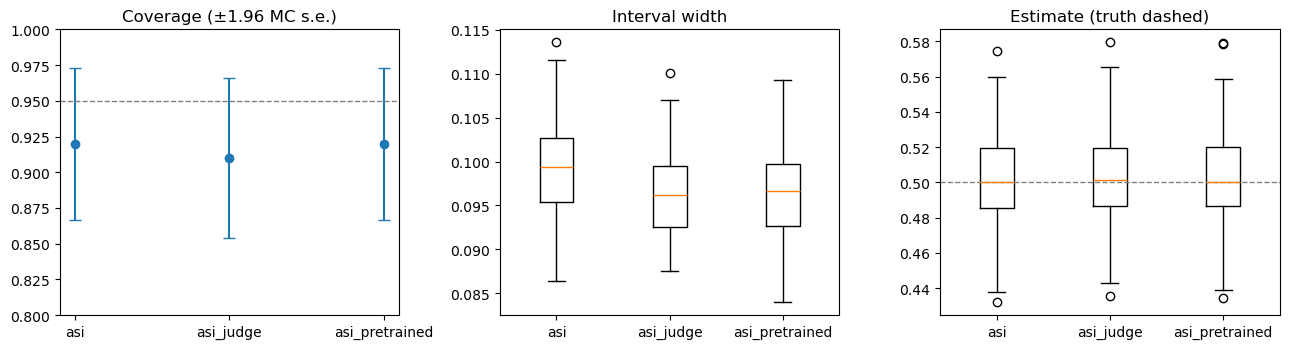

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
policies = list(summary.policy)
x = np.arange(len(policies))
level = 1 - json.loads((RESULTS / 'config.json').read_text())['config']['alpha']

axes[0].errorbar(x, summary.coverage, yerr=1.96 * summary.coverage_mc_se, fmt='o', capsize=4)
axes[0].axhline(level, color='grey', ls='--', lw=1)
axes[0].set(title='Coverage (±1.96 MC s.e.)', xticks=x, xticklabels=policies, ylim=(.8, 1))

axes[1].boxplot([rows.loc[rows.policy == p, 'width'] for p in policies], positions=x)
axes[1].set(title='Interval width', xticks=x, xticklabels=policies)

axes[2].boxplot([rows.loc[rows.policy == p, 'estimate'] for p in policies], positions=x)
axes[2].axhline(truth, color='grey', ls='--', lw=1)
axes[2].set(title='Estimate (truth dashed)', xticks=x, xticklabels=policies)
fig.tight_layout()